# Customer Churn Prediction: Data Analysis and Model Training

**Project:** Customer Churn Prediction Web App (Streamlit + Machine Learning)
**Dataset:** IBM Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`)
**Team:** [Group name] · [Name 1], [Name 2], [Name 3]
**Course:** [Course name] · **Lecturer:** [Lecturer name]

---

## Goal

A telecom company loses revenue every time a customer cancels the service (**churn**).
This notebook builds a machine learning model that predicts whether a customer will churn,
so the company can contact at-risk customers early.

## Contents

1. Setup
2. Load the data
3. Check data quality
4. Clean the data
5. Explore the data (EDA)
6. Prepare the data for the model
7. Train four models
8. Evaluate the models
9. Feature importance
10. Predict one customer
11. Conclusion

The Streamlit app uses the same steps. `train_model.py` runs sections 6–9 and saves the best model to `models/model.pkl`.

## 1. Setup

Import the libraries and set the project settings in one place.

In [1]:
# Data handling
import numpy as np
import pandas as pd

# Charts
import matplotlib.pyplot as plt

# Machine learning
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier

# Display settings
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

In [2]:
# =============================================================================
# PROJECT SETTINGS (the same values as utils.py and train_model.py)
# =============================================================================

DATA_PATH = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"

TARGET = "Churn"          # the column we predict
ID_COL = "customerID"     # identifies a customer, not used by the model

# Columns that contain numbers
NUMERIC_COLS = ["tenure", "MonthlyCharges", "TotalCharges"]

# Columns that contain categories (text values)
CATEGORICAL_COLS = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod",
]

# All input columns of the model
FEATURES = CATEGORICAL_COLS + NUMERIC_COLS

TEST_SIZE = 0.2       # 20% of the customers are kept for testing
RANDOM_STATE = 42     # fixed number, so the results are the same every run

# Chart colors: orange = churned, blue = stayed
CHURN_COLORS = {"Yes": "#E8590C", "No": "#1C7ED6"}
GREY = "#ADB5BD"

## 2. Load the data

In [3]:
raw = pd.read_csv(DATA_PATH)

print(f"Rows (customers): {raw.shape[0]:,}")
print(f"Columns:          {raw.shape[1]}")
raw.head()

Rows (customers): 7,043
Columns:          21


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Column names, data types and the number of non-empty values
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

Each row is one customer. The 21 columns fall into five groups:

| Group | Columns |
| --- | --- |
| ID | customerID |
| Customer | gender, SeniorCitizen, Partner, Dependents |
| Account | tenure (months), Contract, PaperlessBilling, PaymentMethod, MonthlyCharges, TotalCharges |
| Services | PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies |
| Target | Churn (Yes / No) |

`TotalCharges` is a money amount, but its type is `object` (text). Section 3 checks why.

## 3. Check data quality

In [5]:
# Problem 1: TotalCharges is stored as text.
# Try to convert it to numbers. Values that cannot be converted become NaN (missing).
total_as_number = pd.to_numeric(raw["TotalCharges"], errors="coerce")
blank_rows = raw[total_as_number.isna()]

print(f"TotalCharges values that are not numbers: {len(blank_rows)}")
print(f"Their raw value: {blank_rows['TotalCharges'].unique().tolist()}")
blank_rows[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

TotalCharges values that are not numbers: 11
Their raw value: [' ']


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [6]:
# Problem 2: SeniorCitizen uses 0/1, while the other Yes/No columns use text
print("SeniorCitizen values:", sorted(raw["SeniorCitizen"].unique().tolist()))
print("Partner values:      ", sorted(raw["Partner"].unique().tolist()))

SeniorCitizen values: [0, 1]
Partner values:       ['No', 'Yes']


In [7]:
# Other checks: duplicated customers and empty cells
print("Duplicated customer IDs:", raw[ID_COL].duplicated().sum())
print("Empty cells (NaN):      ", raw.isna().sum().sum())

Duplicated customer IDs: 0
Empty cells (NaN):       0


**What we found:**

1. **TotalCharges** has 11 blank values (a single space). All 11 customers have `tenure = 0`:
   they are brand-new customers who have not been billed yet.
2. **SeniorCitizen** is stored as 0/1, while the other yes/no columns use the words "Yes" and "No".
3. There are no duplicated customer IDs and no other empty cells.

## 4. Clean the data

The cleaning function fixes both problems. The app uses the same steps (`clean_data` in `utils.py`).

The 11 blank `TotalCharges` values become missing values (NaN). The model pipeline in section 6
fills them with the median. A value of 0 would also be reasonable for new customers;
either choice affects only 11 of 7,043 rows.

In [8]:
def clean_data(df: pd.DataFrame) -> pd.DataFrame:
    """
    Fix the known problems in the raw churn data.

    Steps:
        1. Convert TotalCharges from text to numbers (blank -> NaN).
        2. Convert SeniorCitizen from 0/1 to No/Yes.

    Returns a cleaned copy. The original DataFrame is not changed.
    """
    df = df.copy()

    # Step 1: TotalCharges -> numbers
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

    # Step 2: SeniorCitizen -> No/Yes
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

    return df


df = clean_data(raw)

print("TotalCharges type now:", df["TotalCharges"].dtype)
print("SeniorCitizen values now:", sorted(df["SeniorCitizen"].unique().tolist()))
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])

TotalCharges type now: float64
SeniorCitizen values now: ['No', 'Yes']
Missing values per column:
TotalCharges    11
dtype: int64


In [9]:
# Summary statistics of the numeric columns
df[NUMERIC_COLS].describe().round(2)

,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


## 5. Explore the data (EDA)

First, two helper functions used by the charts below.

In [10]:
def churn_rate_by(df: pd.DataFrame, column: str) -> pd.DataFrame:
    """Return the churn rate (%) and the number of customers for each value of a column."""
    churned = (df[TARGET] == "Yes").astype(int)
    groups = churned.groupby(df[column], observed=True)

    result = pd.DataFrame()
    result["churn_rate"] = (groups.mean() * 100).round(1)
    result["customers"] = groups.count()
    return result


def plot_churn_rate(ax, df: pd.DataFrame, column: str, title: str) -> None:
    """
    Draw a horizontal bar chart of the churn rate for each value of a column.

    The dashed line shows the overall churn rate, so you can see
    which groups churn more or less than average.
    """
    rates = churn_rate_by(df, column).sort_values("churn_rate")
    overall_rate = (df[TARGET] == "Yes").mean() * 100

    # Groups above the average are orange, the others are grey
    colors = []
    for rate in rates["churn_rate"]:
        if rate > overall_rate:
            colors.append(CHURN_COLORS["Yes"])
        else:
            colors.append(GREY)

    ax.barh(rates.index.astype(str), rates["churn_rate"], color=colors)
    ax.axvline(overall_rate, color="black", linestyle="--", linewidth=1)

    for position, rate in enumerate(rates["churn_rate"]):
        ax.text(rate + 1, position, f"{rate:.1f}%", va="center", fontsize=9,
                bbox=dict(facecolor="white", edgecolor="none", pad=1))

    ax.set_title(title, fontsize=11, loc="left")
    ax.set_xlabel("Churn rate (%)")
    ax.set_xlim(0, max(rates["churn_rate"].max(), overall_rate) * 1.25)

### 5.1 How many customers churn?

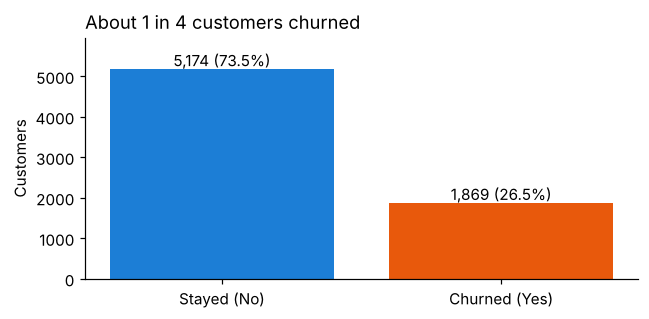

In [11]:
counts = df[TARGET].value_counts()
shares = df[TARGET].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 3))
bars = ax.bar(["Stayed (No)", "Churned (Yes)"], [counts["No"], counts["Yes"]],
              color=[CHURN_COLORS["No"], CHURN_COLORS["Yes"]])

for bar, label in zip(bars, ["No", "Yes"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 80,
            f"{counts[label]:,} ({shares[label]:.1f}%)", ha="center", fontsize=10)

ax.set_title("About 1 in 4 customers churned", loc="left")
ax.set_ylabel("Customers")
ax.set_ylim(0, counts.max() * 1.15)
plt.tight_layout()
plt.show()

The classes are **imbalanced**: 73.5% stayed and 26.5% churned.
A model that always says "No" would already be 73.5% accurate, so accuracy alone is not a good measure.
Section 8 uses recall, F1-score and ROC-AUC as well.

### 5.2 Contract, payment method and internet service

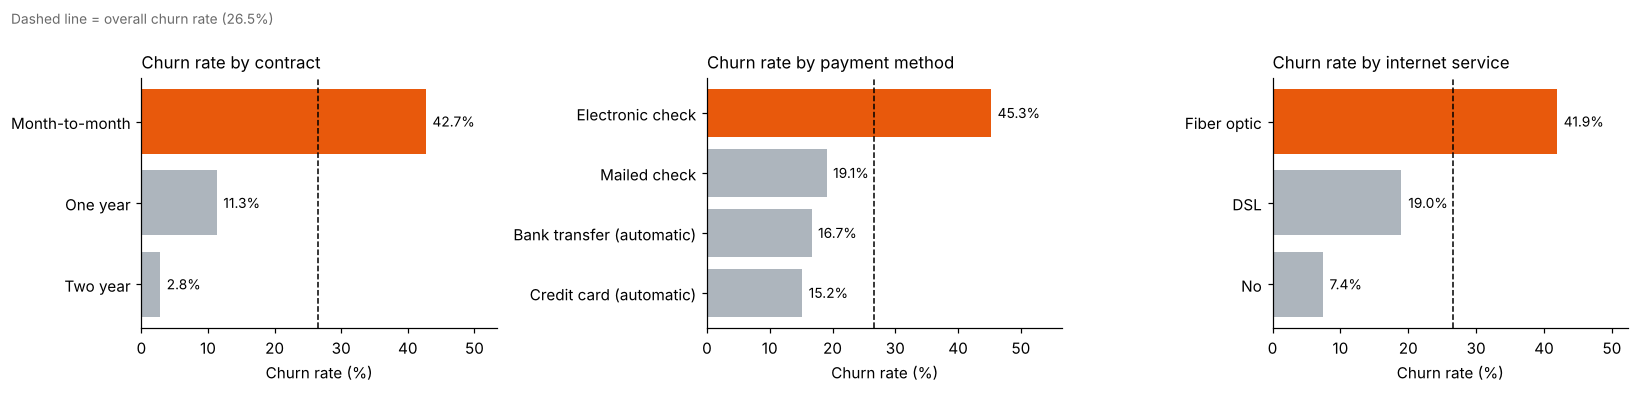

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))

plot_churn_rate(axes[0], df, "Contract", "Churn rate by contract")
plot_churn_rate(axes[1], df, "PaymentMethod", "Churn rate by payment method")
plot_churn_rate(axes[2], df, "InternetService", "Churn rate by internet service")

fig.suptitle("Dashed line = overall churn rate (26.5%)", x=0.01, ha="left", fontsize=9, color="dimgray")
plt.tight_layout()
plt.show()

### 5.3 Tenure and monthly charges

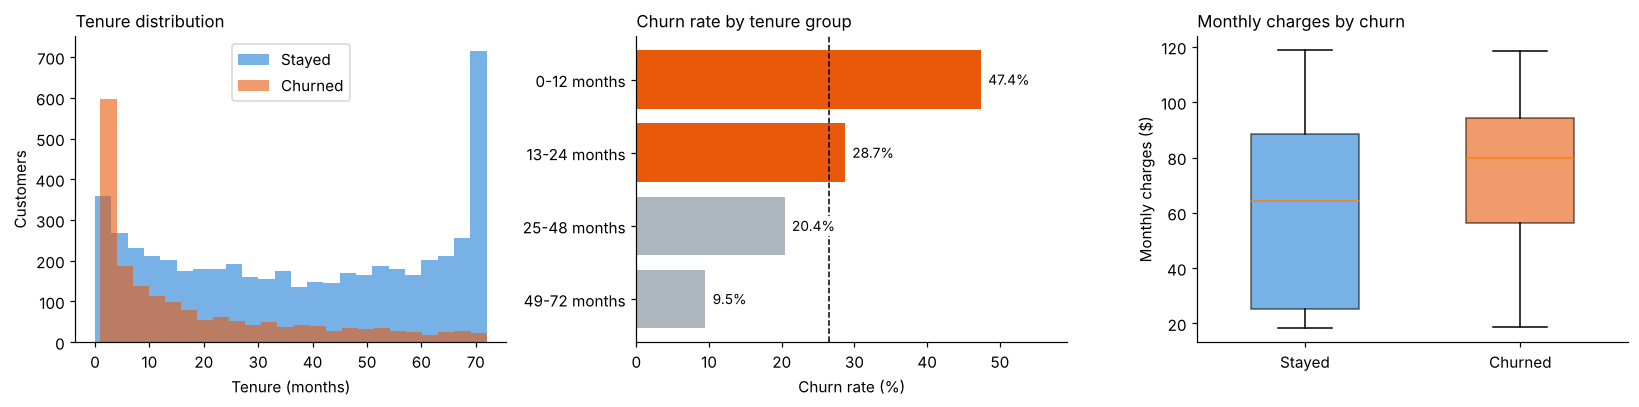

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

# Chart 1: tenure histogram for churned and stayed customers
for label in ["No", "Yes"]:
    tenure_values = df.loc[df[TARGET] == label, "tenure"]
    axes[0].hist(tenure_values, bins=24, alpha=0.6, color=CHURN_COLORS[label],
                 label="Churned" if label == "Yes" else "Stayed")
axes[0].set_title("Tenure distribution", fontsize=11, loc="left")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Customers")
axes[0].legend()

# Chart 2: churn rate by tenure group
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12 months", "13-24 months", "25-48 months", "49-72 months"])
plot_churn_rate(axes[1], df, "tenure_group", "Churn rate by tenure group")

# Chart 3: monthly charges for churned and stayed customers
box_data = [df.loc[df[TARGET] == "No", "MonthlyCharges"],
            df.loc[df[TARGET] == "Yes", "MonthlyCharges"]]
box = axes[2].boxplot(box_data, patch_artist=True, widths=0.5)
axes[2].set_xticks([1, 2], ["Stayed", "Churned"])
for patch, label in zip(box["boxes"], ["No", "Yes"]):
    patch.set_facecolor(CHURN_COLORS[label])
    patch.set_alpha(0.6)
axes[2].set_title("Monthly charges by churn", fontsize=11, loc="left")
axes[2].set_ylabel("Monthly charges ($)")

plt.tight_layout()
plt.show()

# The tenure group is only for this chart, so remove it again
df = df.drop(columns="tenure_group")

In [14]:
# Median tenure and monthly charges for each group
df.groupby(TARGET)[["tenure", "MonthlyCharges"]].median().round(2)

,tenure,MonthlyCharges
Churn,,
No,38.0,64.43
Yes,10.0,79.65


### 5.4 Customer details and support services

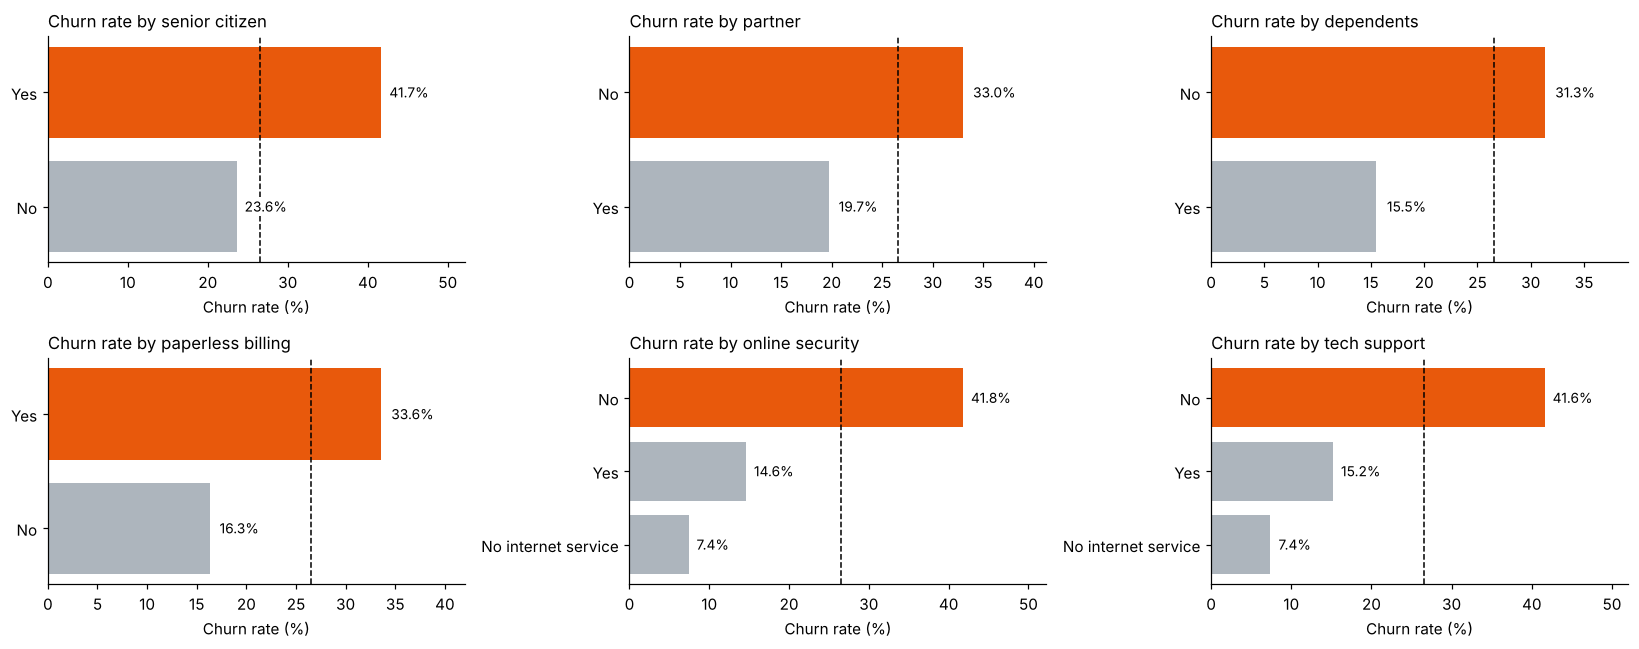

In [15]:
columns_to_plot = [
    ("SeniorCitizen", "Senior citizen"),
    ("Partner", "Partner"),
    ("Dependents", "Dependents"),
    ("PaperlessBilling", "Paperless billing"),
    ("OnlineSecurity", "Online security"),
    ("TechSupport", "Tech support"),
]

fig, axes = plt.subplots(2, 3, figsize=(15, 6))

for ax, (column, title) in zip(axes.flatten(), columns_to_plot):
    plot_churn_rate(ax, df, column, f"Churn rate by {title.lower()}")

plt.tight_layout()
plt.show()

In [16]:
# Gender: is there a difference?
churn_rate_by(df, "gender")

,churn_rate,customers
gender,,
Female,26.9,3488
Male,26.2,3555


### 5.5 Correlation between the numeric columns

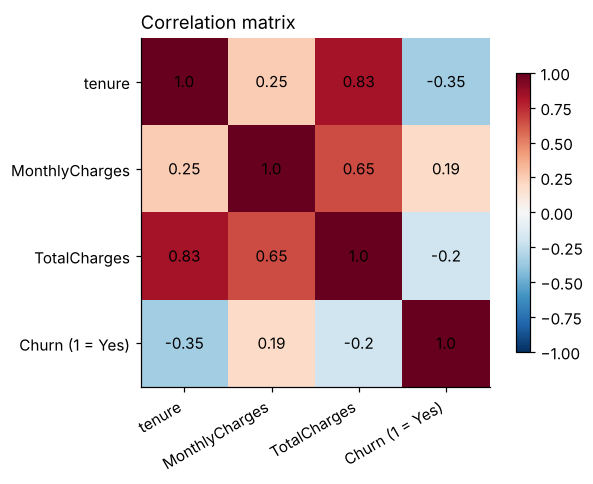

In [17]:
numeric_table = df[NUMERIC_COLS].copy()
numeric_table["Churn (1 = Yes)"] = (df[TARGET] == "Yes").astype(int)
correlation = numeric_table.corr().round(2)

fig, ax = plt.subplots(figsize=(6, 4.5))
image = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)

ax.set_xticks(range(len(correlation.columns)), correlation.columns, rotation=30, ha="right")
ax.set_yticks(range(len(correlation.index)), correlation.index)

for row in range(len(correlation.index)):
    for col in range(len(correlation.columns)):
        ax.text(col, row, correlation.iloc[row, col], ha="center", va="center", fontsize=10)

fig.colorbar(image, ax=ax, shrink=0.8)
ax.set_title("Correlation matrix", loc="left")
plt.tight_layout()
plt.show()

### 5.6 EDA findings

| Finding | Evidence |
| --- | --- |
| Contract type is the biggest difference | Month-to-month 42.7% churn vs one-year 11.3% and two-year 2.8% |
| New customers churn most | 47.4% churn in the first 12 months vs 9.5% after 4 years; median tenure 10 vs 38 months |
| Electronic check payers churn more | 45.3% vs 15–19% for the other payment methods |
| Fiber optic customers churn more | 41.9% vs 19.0% for DSL and 7.4% with no internet |
| Higher bills go with churn | Median monthly charge $79.65 for churned vs $64.43 for stayed |
| Support services go with staying | No tech support 41.6% vs 15.2% with it; online security shows the same pattern |
| Senior citizens and single customers churn more | Senior 41.7% vs 23.6%; no partner 33.0% vs 19.7% |
| Gender makes no difference | Female 26.9% vs male 26.2% |
| TotalCharges mostly repeats tenure | Correlation 0.83 between tenure and TotalCharges |

These patterns guide the retention suggestions in the app (for example: offer a longer contract,
automatic payment, or tech support).

## 6. Prepare the data for the model

**Steps:**

1. Separate the inputs (X) from the target (y). `customerID` is left out because it carries no information.
2. Split the customers: 80% for training, 20% for testing. `stratify=y` keeps the same churn rate in both parts.
3. Build a preprocessing step:
    - numeric columns: fill missing values with the median, then scale them;
    - categorical columns: fill missing values with the most common value, then one-hot encode them.

The preprocessing is put inside a **pipeline** together with the model. Then the app can give the
pipeline raw customer data, and the pipeline prepares it in exactly the same way as in training.

In [18]:
# Step 1: inputs and target
X = df[FEATURES]
y = (df[TARGET] == "Yes").astype(int)   # 1 = churned, 0 = stayed

# Step 2: train/test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Training set: {len(X_train):,} customers, churn rate {y_train.mean():.1%}")
print(f"Test set:     {len(X_test):,} customers, churn rate {y_test.mean():.1%}")

Training set: 5,634 customers, churn rate 26.5%
Test set:     1,409 customers, churn rate 26.5%


In [19]:
# Step 3: preprocessing
def build_preprocessor() -> ColumnTransformer:
    """Fill missing values, scale numbers and one-hot encode categories."""
    numeric_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ])

    categorical_steps = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])

    return ColumnTransformer([
        ("num", numeric_steps, NUMERIC_COLS),
        ("cat", categorical_steps, CATEGORICAL_COLS),
    ])


# Show how many columns the model receives after one-hot encoding
example = build_preprocessor().fit(X_train)
print(f"Columns before preprocessing: {X_train.shape[1]}")
print(f"Columns after preprocessing:  {example.transform(X_train.head()).shape[1]}")

Columns before preprocessing: 19
Columns after preprocessing:  46


## 7. Train four models

| Model | Why we try it |
| --- | --- |
| Logistic Regression | Simple, fast and easy to explain; a good baseline |
| Decision Tree | A set of if/else rules that is easy to read; `max_depth=5` (the team notebook's setting) keeps it small |
| Random Forest | Many decision trees voting together; handles non-linear patterns |
| XGBoost | Gradient-boosted trees; often the strongest on tabular data |

Only 26.5% of customers churn. To make the models pay more attention to churners, Logistic Regression,
Decision Tree and Random Forest use `class_weight="balanced"`, and XGBoost uses `scale_pos_weight`
(number of stayed customers ÷ number of churned customers).

In [20]:
positive_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight for XGBoost: {positive_weight:.2f}")

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=positive_weight,
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    ),
}

scale_pos_weight for XGBoost: 2.77


In [21]:
trained_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("prep", build_preprocessor()),
        ("model", model),
    ])
    pipeline.fit(X_train, y_train)
    trained_pipelines[name] = pipeline
    print(f"Trained: {name}")

Trained: Logistic Regression


Trained: Decision Tree


Trained: Random Forest


Trained: XGBoost


### 7.1 What the Decision Tree learned

A decision tree is easy to explain: each box is a yes/no question about one column.
The chart shows the first 2 levels of the tree (the full tree has 5 levels).
In this chart, orange boxes lean towards **staying** and blue boxes towards **churn**; a darker colour means a clearer majority.

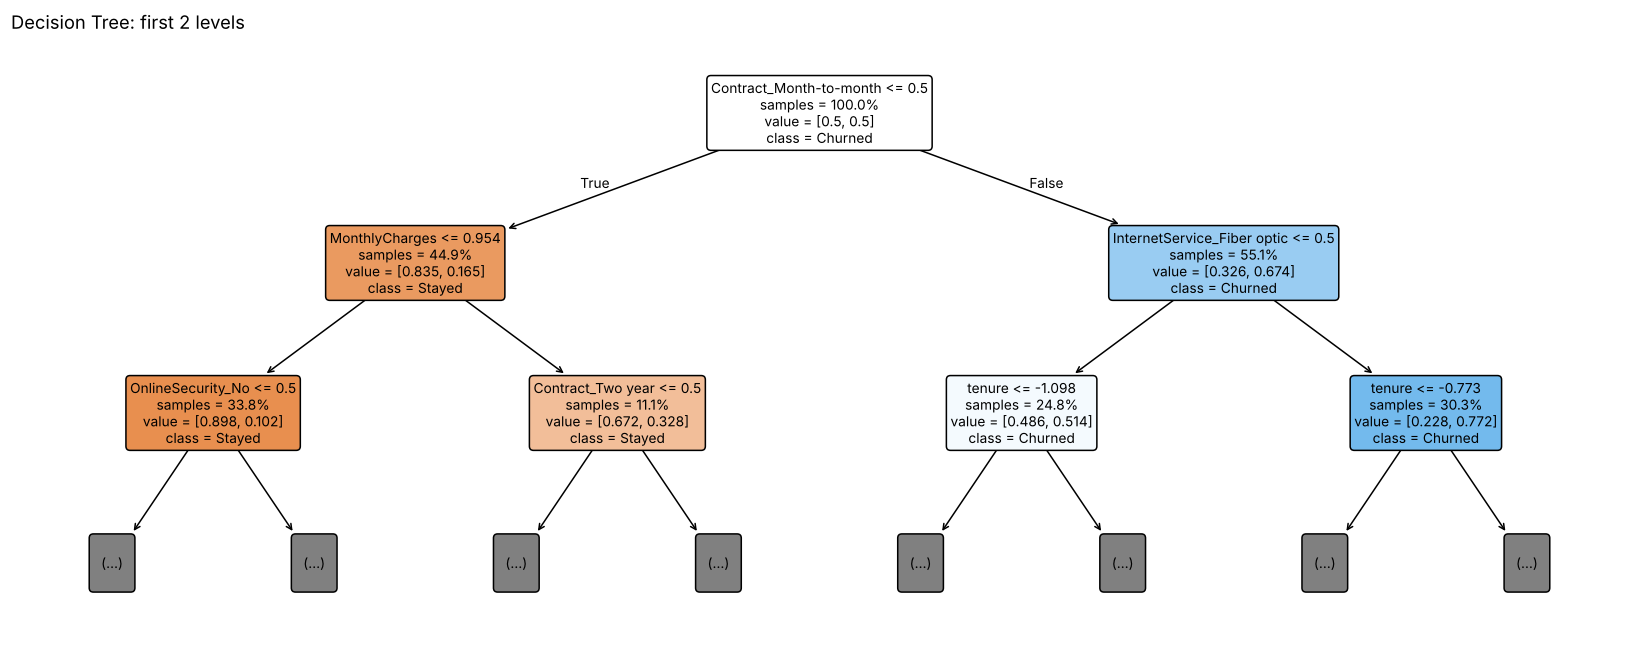

In [22]:
from sklearn.tree import plot_tree

tree_pipeline = trained_pipelines["Decision Tree"]

# Column names after preprocessing, for example "cat__Contract_Month-to-month"
feature_names = tree_pipeline.named_steps["prep"].get_feature_names_out()
feature_names = [name.split("__", 1)[1] for name in feature_names]   # remove the "num__" / "cat__" prefix

fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(
    tree_pipeline.named_steps["model"],
    max_depth=2,
    feature_names=feature_names,
    class_names=["Stayed", "Churned"],
    filled=True,
    rounded=True,
    impurity=False,
    proportion=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Decision Tree: first 2 levels", loc="left")
plt.tight_layout()
plt.show()

The first question is about the contract. Customers on a one-year or two-year contract (True, left) mostly stay.
Month-to-month customers (False, right) lean towards churn, especially with fiber optic internet and a short tenure.
Values for numeric columns are scaled (section 6), so a split such as `tenure <= -1.098` means
"tenure below a certain number of months", not a negative tenure.

## 8. Evaluate the models

All results below are measured on the **test set**: 1,409 customers the models never saw during training.

| Metric | Meaning |
| --- | --- |
| Accuracy | Share of all predictions that are correct |
| Precision | Of the customers predicted to churn, how many really churned |
| Recall | Of the customers who really churned, how many the model found |
| F1-score | Balance between precision and recall |
| ROC-AUC | How well the model ranks churners above non-churners (0.5 = random, 1 = perfect) |

A customer is predicted to churn when the churn probability is 50% or more.

In [23]:
rows = []
probabilities = {}

for name, pipeline in trained_pipelines.items():
    # predict_proba gives [probability of staying, probability of churning]
    churn_probability = pipeline.predict_proba(X_test)[:, 1]
    prediction = (churn_probability >= 0.5).astype(int)
    probabilities[name] = churn_probability

    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, prediction),
        "Precision": precision_score(y_test, prediction),
        "Recall": recall_score(y_test, prediction),
        "F1-score": f1_score(y_test, prediction),
        "ROC-AUC": roc_auc_score(y_test, churn_probability),
    })

results = pd.DataFrame(rows).set_index("Model").round(3)
results.sort_values("F1-score", ascending=False)

,Accuracy,Precision,Recall,F1-score,ROC-AUC
Model,,,,,
Random Forest,0.760,0.533,0.767,0.629,0.841
XGBoost,0.756,0.527,0.773,0.627,0.840
Decision Tree,0.755,0.527,0.759,0.622,0.832
Logistic Regression,0.737,0.503,0.783,0.613,0.841


In [24]:
# Choose the best model by F1-score (the same rule as train_model.py)
best_name = results["F1-score"].idxmax()
best_pipeline = trained_pipelines[best_name]
print(f"Best model: {best_name} (F1-score {results.loc[best_name, 'F1-score']:.3f})")

Best model: Random Forest (F1-score 0.629)


### 8.1 Confusion matrices

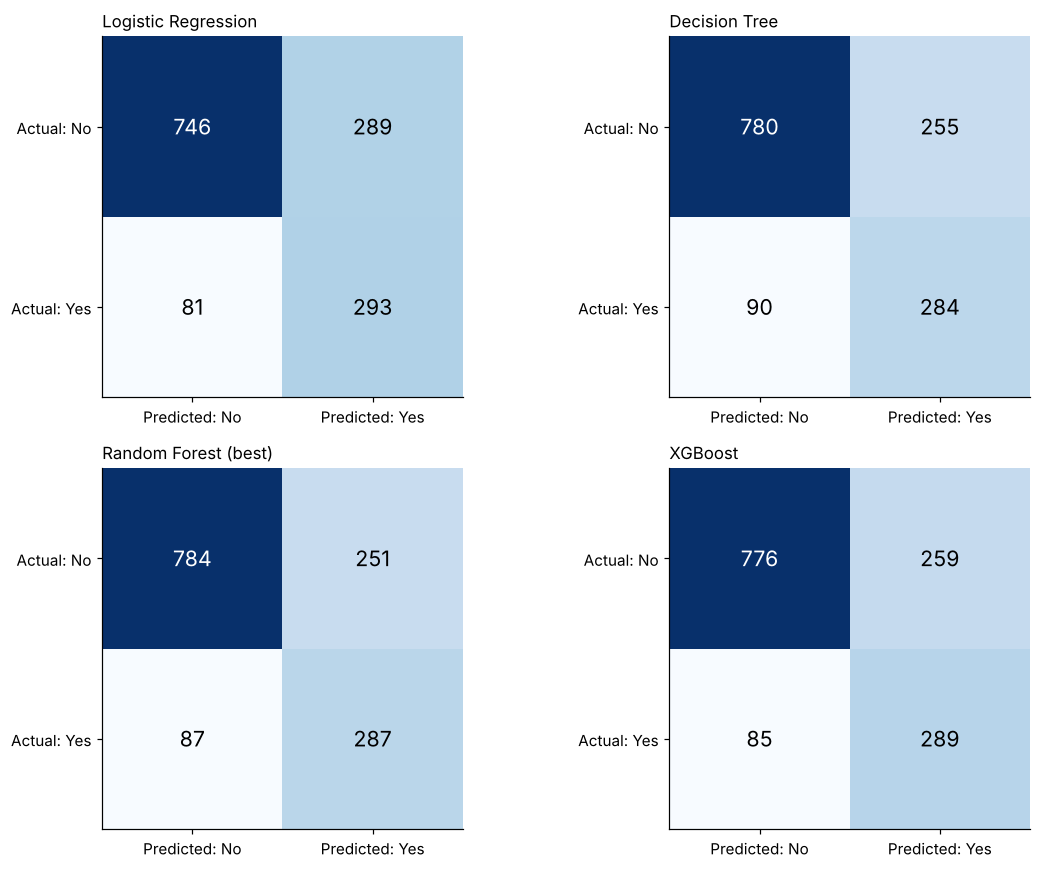

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, (name, churn_probability) in zip(axes.flatten(), probabilities.items()):
    prediction = (churn_probability >= 0.5).astype(int)
    matrix = confusion_matrix(y_test, prediction)

    ax.imshow(matrix, cmap="Blues")
    for row in range(2):
        for col in range(2):
            color = "white" if matrix[row, col] > matrix.max() / 2 else "black"
            ax.text(col, row, f"{matrix[row, col]:,}", ha="center", va="center",
                    fontsize=14, color=color)

    ax.set_xticks([0, 1], ["Predicted: No", "Predicted: Yes"])
    ax.set_yticks([0, 1], ["Actual: No", "Actual: Yes"])
    ax.set_title(name + (" (best)" if name == best_name else ""), loc="left", fontsize=11)

plt.tight_layout()
plt.show()

In [26]:
# Read the confusion matrix of the best model
best_prediction = (probabilities[best_name] >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, best_prediction).ravel()

print(f"{best_name} on {len(y_test):,} test customers:")
print(f"  Churners found (true positives):   {tp} of {tp + fn}")
print(f"  Churners missed (false negatives): {fn}")
print(f"  False alarms (false positives):    {fp} of {tn + fp} customers who stayed")

Random Forest on 1,409 test customers:
  Churners found (true positives):   287 of 374
  Churners missed (false negatives): 87
  False alarms (false positives):    251 of 1035 customers who stayed


### 8.2 ROC curves

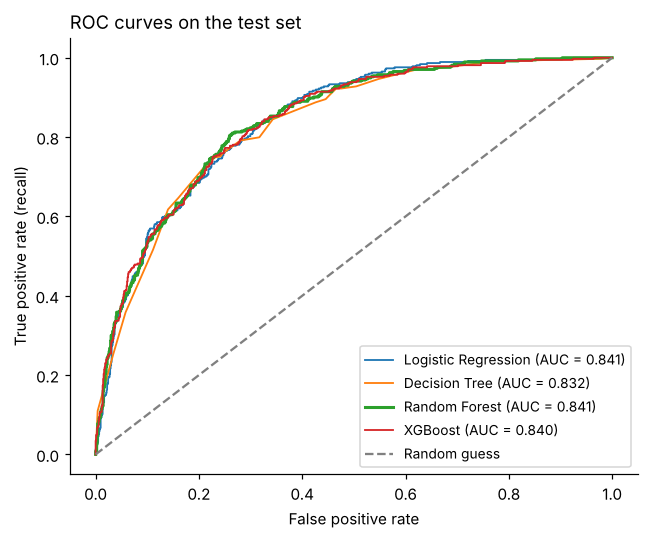

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))

for name, churn_probability in probabilities.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, churn_probability)
    auc = roc_auc_score(y_test, churn_probability)
    ax.plot(false_positive_rate, true_positive_rate, linewidth=2 if name == best_name else 1.2,
            label=f"{name} (AUC = {auc:.3f})")

ax.plot([0, 1], [0, 1], color="gray", linestyle="--", label="Random guess")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves on the test set", loc="left")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

### 8.3 Classification report of the best model

In [28]:
print(classification_report(y_test, best_prediction, target_names=["Stayed (0)", "Churned (1)"], digits=3))

              precision    recall  f1-score   support

  Stayed (0)      0.900     0.757     0.823      1035
 Churned (1)      0.533     0.767     0.629       374

    accuracy                          0.760      1409
   macro avg      0.717     0.762     0.726      1409
weighted avg      0.803     0.760     0.771      1409



## 9. Feature importance

**Permutation importance:** shuffle the values of one column and measure how much the ROC-AUC drops.
If the score drops a lot, the model depends on that column. The app shows the same chart on the
Model Performance page.

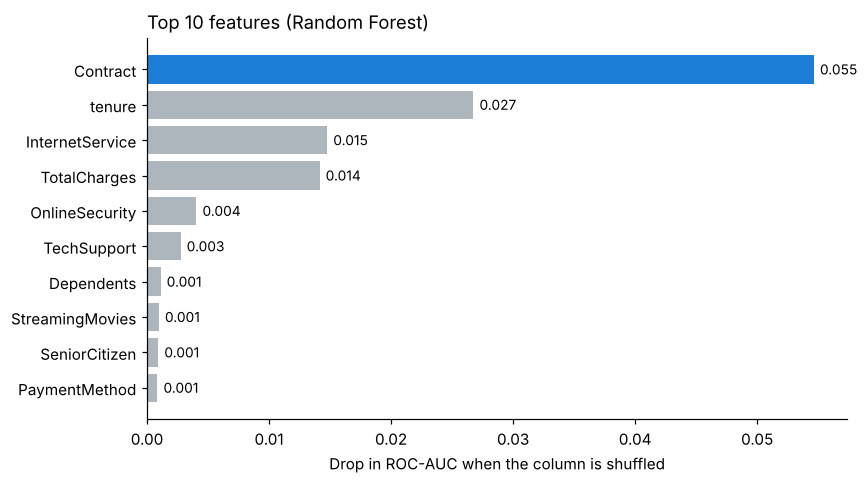

In [29]:
importance_result = permutation_importance(
    best_pipeline,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

importance = pd.Series(importance_result.importances_mean, index=FEATURES)
importance = importance.sort_values(ascending=False)

top = importance.head(10).sort_values()
colors = [GREY] * (len(top) - 1) + [CHURN_COLORS["No"]]   # highlight the most important

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(top.index, top.values, color=colors)
for position, value in enumerate(top.values):
    ax.text(value + 0.0005, position, f"{value:.3f}", va="center", fontsize=9)

ax.set_title(f"Top 10 features ({best_name})", loc="left")
ax.set_xlabel("Drop in ROC-AUC when the column is shuffled")
plt.tight_layout()
plt.show()

In [30]:
# The 5 least useful columns
importance.tail(5).round(4)

StreamingTV         0.0002
PhoneService       -0.0000
MonthlyCharges     -0.0003
DeviceProtection   -0.0005
gender             -0.0006
dtype: float64

## 10. Predict one customer

The app's **Predict a Customer** page does this for any customer typed into the form.
Here we test one new, high-risk-looking customer.

In [31]:
new_customer = pd.DataFrame([{
    "gender": "Female",
    "SeniorCitizen": "No",
    "Partner": "No",
    "Dependents": "No",
    "tenure": 3,
    "PhoneService": "Yes",
    "MultipleLines": "No",
    "InternetService": "Fiber optic",
    "OnlineSecurity": "No",
    "OnlineBackup": "No",
    "DeviceProtection": "No",
    "TechSupport": "No",
    "StreamingTV": "Yes",
    "StreamingMovies": "Yes",
    "Contract": "Month-to-month",
    "PaperlessBilling": "Yes",
    "PaymentMethod": "Electronic check",
    "MonthlyCharges": 95.00,
    "TotalCharges": 285.00,
}])

churn_probability = best_pipeline.predict_proba(new_customer[FEATURES])[0, 1]

# Risk levels used in the app
if churn_probability >= 0.70:
    risk = "High"
elif churn_probability >= 0.40:
    risk = "Medium"
else:
    risk = "Low"

print(f"Churn probability: {churn_probability:.1%}")
print(f"Risk level:        {risk}")

Churn probability: 89.7%
Risk level:        High


In [32]:
# Check: the app's saved model (from train_model.py) should give the same test results
import json
from pathlib import Path

metrics_path = Path("models/metrics.json")
if metrics_path.exists():
    saved = json.loads(metrics_path.read_text())
    saved_best = saved["best_model"]
    print(f"App model: {saved_best}, F1-score {saved['models'][saved_best]['f1']:.3f}")
    print(f"Notebook:  {best_name}, F1-score {results.loc[best_name, 'F1-score']:.3f}")
else:
    print("models/metrics.json not found. Run `python train_model.py` to train the app's model.")

App model: Random Forest, F1-score 0.629
Notebook:  Random Forest, F1-score 0.629


## 11. Conclusion

**Model.** Random Forest is the best of the four models, with an F1-score of 0.629, recall of 0.767 and
ROC-AUC of 0.841 on the test set. It finds about 3 in 4 customers who churn. The four models score
within 0.02 F1 of each other, so the result depends more on the data than on the algorithm.

**What drives churn.** Contract type is the strongest signal, followed by tenure, internet service and
total charges. Customers on month-to-month contracts, in their first year, with fiber optic internet,
paying by electronic check and without tech support are the most likely to leave.

**Recommendations for the business:**

1. Offer discounts for moving from month-to-month to one-year or two-year contracts.
2. Give new customers extra attention in their first 12 months (welcome calls, onboarding).
3. Encourage automatic payment instead of electronic check.
4. Offer free trials of tech support and online security.
5. Review fiber optic pricing and service quality.

**Limitations:**

- The dataset is a single snapshot of 7,043 customers from one (sample) company; patterns may differ elsewhere.
- About half of the customers flagged as churners actually stay (precision 0.53), so retention offers
  should be low-cost, such as a call or a small discount.
- The model predicts *whether* a customer churns, not *when*.

**Possible improvements:** tune the model settings (for example with `GridSearchCV`), adjust the
50% decision threshold to trade recall against precision, and add newer data over time.